<a href="https://colab.research.google.com/github/ASHIK-77/ML-LAB/blob/main/EXP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score

In [20]:
housing=fetch_california_housing()
data=pd.DataFrame(
    housing.data,columns=housing.feature_names
)
data["price"]=housing.target

In [21]:
x=data[["AveRooms"]].values
y=data["price"].values
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [22]:
w=0
b=0
learning_rate=0.01
epochs=1000
cost_history=[]
n=len(x_train_scaled)
for i in range(epochs):
  y_pred=w*x_train_scaled.flatten()+b
  dw=(1/n)*np.sum((y_pred-y_train)*x_train_scaled.flatten())
  db=(1/n)*np.sum(y_pred-y_train)
  w=w-learning_rate*dw
  b=b-learning_rate*db
  cost=(1/(2*n))*np.sum((y_pred-y_train)**2)
  cost_history.append(cost)
  if i%100 == 0:
    print(f"Epoch {i}: Cost={cost:.4f}")
y_pred_gd=w*x_test_scaled.flatten()+b
print("Gradient Descent")
print("------------------")
print("Weignt:",w)
print("Bias:",b)
print("MSE:",mean_squared_error(y_test,y_pred_gd))
print("R2 Score:",r2_score(y_test,y_pred_gd))

Epoch 0: Cost=2.8149
Epoch 100: Cost=0.9414
Epoch 200: Cost=0.6904
Epoch 300: Cost=0.6568
Epoch 400: Cost=0.6523
Epoch 500: Cost=0.6517
Epoch 600: Cost=0.6516
Epoch 700: Cost=0.6516
Epoch 800: Cost=0.6516
Epoch 900: Cost=0.6516
Gradient Descent
------------------
Weignt: 0.18323090648660517
Bias: 2.071857488845021
MSE: 1.292327655590046
R2 Score: 0.013798228607320828


In [23]:
x_mean=np.mean(x_train)
y_mean=np.mean(y_train)
w_ne=np.sum(
    (x_train.flatten()-x_mean)*
     (y_train-y_mean)
     )/(np.sum
      (x_train.flatten()-x_mean)**2
        )
b_ne=y_mean-w_ne*x_mean
y_pred_ne=w_ne*x_test.flatten()+b_ne
print("Normal Equation")
print("-----------------")
print("Weight: ",w_ne)
print("Bias:",b_ne)
print("MSE:",mean_squared_error(y_test,y_pred_ne))
print("R2 SCORE:",r2_score(y_test,y_pred_ne))

Normal Equation
-----------------
Weight:  1.1611765635748763e+26
Bias: -6.311267523311533e+26
MSE: 1.0529818885944579e+53
R2 SCORE: -8.035521017323817e+52


In [24]:
idx=np.argsort(x_test.flatten())
x_sorted=x_test.flatten()[idx]
y_test_sorted=y_test[idx]
y_pred_gd_sorted= y_pred_gd[idx]
y_pred_ne_sorted=y_pred_ne[idx]

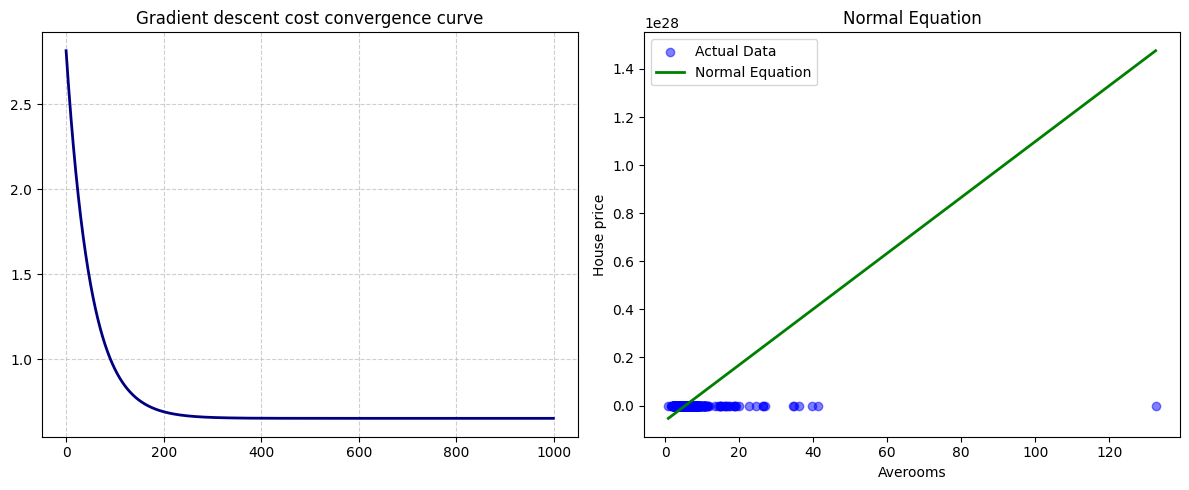

In [26]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(
    cost_history,
    color='navy',
    linewidth=2
)
plt.title('Gradient descent cost convergence curve')
plt.grid(True,linestyle='--',alpha=0.6)
plt.subplot(1,2,2)
plt.scatter(
            x_test,
            y_test,
            color='blue',
            alpha=0.5,
            label='Actual Data'
            )
plt.plot(
    x_sorted,
    y_pred_ne_sorted,
    color='green',
    linewidth=2,
    label="Normal Equation"
)
plt.xlabel("Averooms")
plt.ylabel("House price")
plt.title("Normal Equation")
plt.legend()
plt.tight_layout()
plt.show()